<a href="https://colab.research.google.com/github/AlfredaDhaifullah04/PCVK_Ganjil_2026/blob/main/PCVK_M1_W1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Praktikum Modul 1 - Pengantar Citra Digital dan Visi Komputer



## Persiapan (Import Libraries)
Jalankan sel ini terlebih dahulu untuk memuat semua pustaka yang dibutuhkan.


In [1]:
import numpy as np
import pandas as pd
import cv2 as cv
from google.colab.patches import cv2_imshow
from skimage import io
import matplotlib.pyplot as plt
import random


## Praktikum D2: Membaca dan Menampilkan Citra


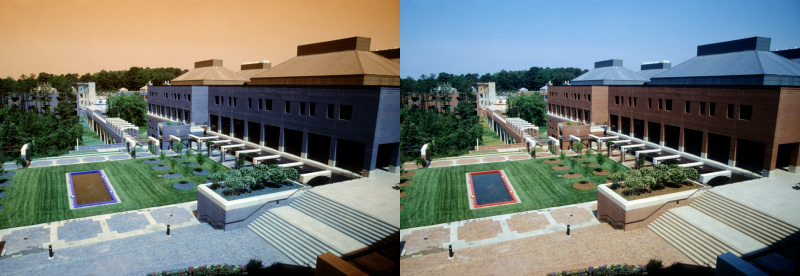

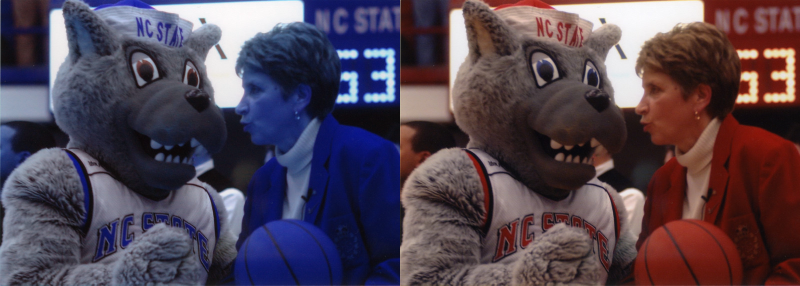



Resolusi image: tinggi x lebar = 286 x 400


In [2]:
# Langkah 2: Membaca Image dari URL
urls = [
    "https://iiif.lib.ncsu.edu/iiif/0052574/full/800,/0/default.jpg",
    "https://iiif.lib.ncsu.edu/iiif/0016007/full/800,/0/default.jpg"
]

for url in urls:
    image = io.imread(url)
    image = cv.resize(image, (0,0), fx=0.5, fy=0.5)
    image_2 = cv.cvtColor(image, cv.COLOR_BGR2RGB)

    # Menggabungkan gambar (hconcat)
    final_frame = cv.hconcat((image, image_2))
    cv2_imshow(final_frame)
    print('\n')

# Langkah 3: Melihat ukuran file image
tinggi = image_2.shape[0]
lebar = image_2.shape[1]
print(f"Resolusi image: tinggi x lebar = {tinggi} x {lebar}")


### Tugas Praktikum D2


Tugas 2: Garis Vertikal dan Diagonal


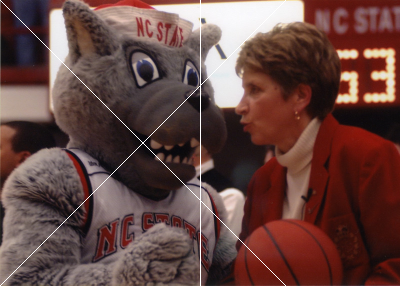


Tugas 3: Garis Horizontal di Tengah


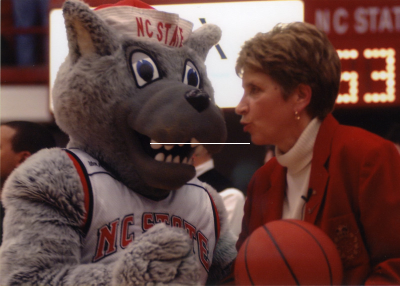


Tugas 4: Kotak Putih


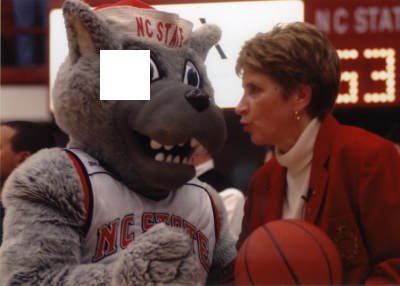

In [3]:
# Menggunakan citra terakhir (image_2) sebagai bahan tugas

# 2. Garis vertikal dan diagonal
img_tugas2 = image_2.copy()
# Vertikal di tengah
img_tugas2[:, int(lebar/2)] = [255, 255, 255]
# Diagonal
for i in range(min(tinggi, lebar)):
    img_tugas2[i, i] = [255, 255, 255] # Diagonal utama
    img_tugas2[i, min(lebar-1, tinggi-1) - i] = [255, 255, 255] # Diagonal sekunder
print("Tugas 2: Garis Vertikal dan Diagonal")
cv2_imshow(img_tugas2)

# 3. Garis horizontal dengan panjang tertentu di tengah
img_tugas3 = image_2.copy()
panjang = 100
start_x = int((lebar - panjang) / 2)
img_tugas3[int(tinggi/2), start_x:start_x+panjang] = [255, 255, 255]
print("\nTugas 3: Garis Horizontal di Tengah")
cv2_imshow(img_tugas3)

# 4. Kotak pixel warna putih di sembarang tempat
img_tugas4 = image_2.copy()
start_y, start_x = 50, 100
panjang_kotak = 50
img_tugas4[start_y:start_y+panjang_kotak, start_x:start_x+panjang_kotak] = [255, 255, 255]
print("\nTugas 4: Kotak Putih")
cv2_imshow(img_tugas4)


## Praktikum D3: Pengolahan Citra Dasar dan Channel Warna
Untuk mempermudah tanpa Google Drive mount, kita menggunakan citra dari URL sebelumnya. Jika ingin menggunakan gambar dari GDrive, silakan *uncomment* kode mount drive di bawah.


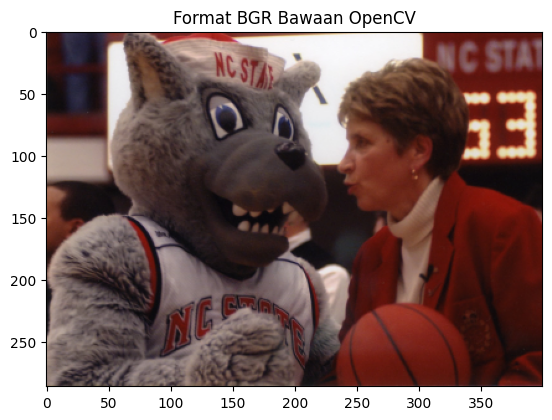

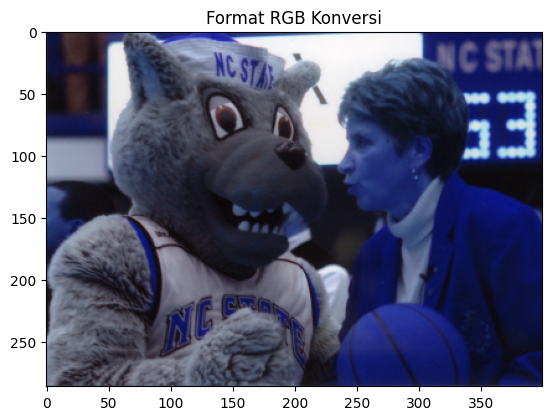

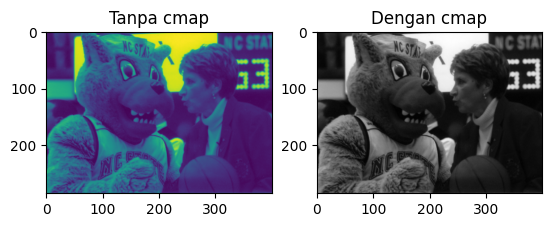

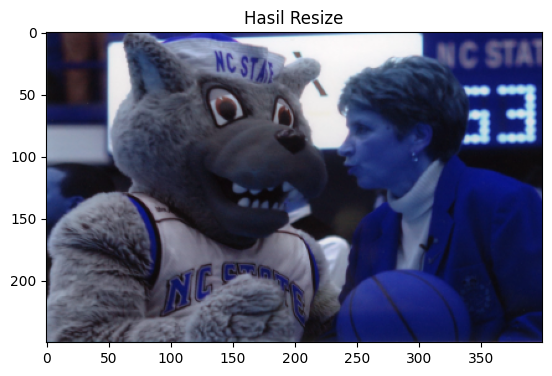

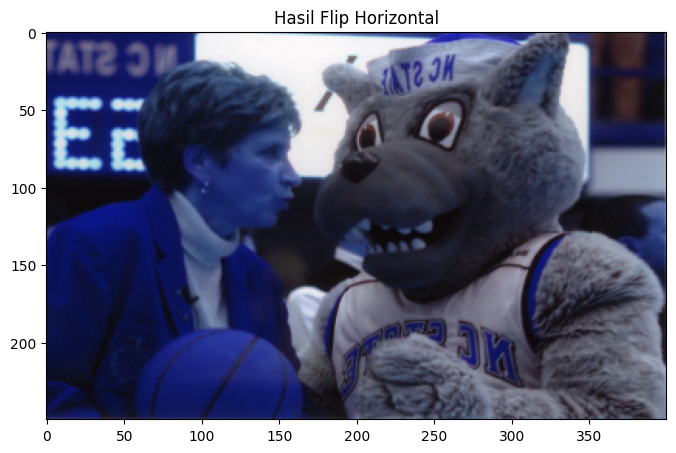

error: OpenCV(5.0.0) /io/opencv/modules/imgproc/src/drawing_text.cpp:1430: error: (-215:Assertion failed) img.depth() == CV_8U in function 'putText'


In [4]:
# Mount Google Drive (Opsional)
# from google.colab import drive
# drive.mount('/content/drive')

# Menggunakan citra sample yang sudah ada (image_2)
img_sample = cv.cvtColor(image_2, cv.COLOR_RGB2BGR) # Kembalikan ke format awal BGR OpenCV

# 2. Menampilkan gambar dengan Matplotlib
plt.imshow(img_sample)
plt.title("Format BGR Bawaan OpenCV")
plt.show()

imgRGB = cv.cvtColor(img_sample, cv.COLOR_BGR2RGB)
plt.imshow(imgRGB)
plt.title("Format RGB Konversi")
plt.show()

# 3. Menampilkan citra Grayscale
img_gray = cv.cvtColor(img_sample, cv.COLOR_BGR2GRAY)
plt.subplot(1,2,1)
plt.imshow(img_gray)
plt.title("Tanpa cmap")

plt.subplot(1,2,2)
plt.imshow(img_gray, cmap="gray")
plt.title("Dengan cmap")
plt.show()

# 4. Resizing
imgRGBsmall = cv.resize(imgRGB, (400, 250))
plt.imshow(imgRGBsmall)
plt.title("Hasil Resize")
plt.show()

# 5. Flipping
imgBalik = cv.flip(imgRGBsmall, 1)
fig = plt.figure(figsize=(8,8))
ax = fig.add_subplot(111)
ax.imshow(imgBalik)
plt.title("Hasil Flip Horizontal")
plt.show()

# 6. Geometri 2D OpenCV
black_img = np.zeros(shape=(512,512,3), dtype=np.int16)
cv.rectangle(black_img, pt1=(384,8), pt2=(510,150), color=(0,255,0), thickness=10)
cv.circle(black_img, center=(100,100), radius=50, color=(255,0,0), thickness=8)
cv.line(black_img, pt1=(0,0), pt2=(512,512), color=(255,255,255), thickness=5)
font = cv.FONT_HERSHEY_SIMPLEX
cv.putText(black_img, text='Hello', org=(10,500), fontFace=font, fontScale=4, color=(255,255,0), thickness=2, lineType=cv.LINE_AA)

plt.imshow(black_img)
plt.title("Geometri 2D OpenCV")
plt.show()


### Tugas Praktikum D3


In [ ]:
img_tugasD3 = imgRGB.copy()

# 1. Menggunakan figsize
plt.figure(figsize=(10,5))
plt.imshow(img_tugasD3)
plt.title("Tugas 1: Penggunaan figsize (Resolusi matriks citra tidak berubah, hanya ukuran plotnya)")
plt.show()

# 2. Tampilkan image Red-Blue (Green dinolkan) dan Green-Blue (Red dinolkan)
img_RB = img_tugasD3.copy()
img_RB[:, :, 1] = 0 # Nolkan kanal Green (Indeks 1)

img_GB = img_tugasD3.copy()
img_GB[:, :, 0] = 0 # Nolkan kanal Red (Indeks 0)

fig, axs = plt.subplots(1, 2, figsize=(10,5))
axs[0].imshow(img_RB)
axs[0].set_title("Red-Blue Channel")
axs[1].imshow(img_GB)
axs[1].set_title("Green-Blue Channel")
plt.show()

# 3. Tampilkan image baris 20-115, kolom 25-120
roi_1 = img_tugasD3[20:115, 25:120]
plt.imshow(roi_1)
plt.title("Tugas 3: Baris 20-115, Kolom 25-120")
plt.show()

# 4. Tampilkan image baris 5-30, semua kolom, channel Red saja
roi_red = img_tugasD3[5:30, :, 0]
plt.imshow(roi_red, cmap='gray')
plt.title("Tugas 4: Baris 5-30, Semua Kolom, Red Channel")
plt.show()

# 5. Buat 5 kotak berbagai ukuran dan warna random
img_boxes = img_tugasD3.copy()
for _ in range(5):
    pt1 = (random.randint(0, lebar//2), random.randint(0, tinggi//2))
    pt2 = (random.randint(lebar//2, lebar), random.randint(tinggi//2, tinggi))
    color = (random.randint(0,255), random.randint(0,255), random.randint(0,255))
    cv.rectangle(img_boxes, pt1, pt2, color, thickness=3)
plt.imshow(img_boxes)
plt.title("Tugas 5: 5 Kotak Random")
plt.show()

# 6. Tampilkan image posisi terbalik (Flip Vertikal & Horizontal)
plt.imshow(cv.flip(img_tugasD3, -1))
plt.title("Tugas 6: Posisi Terbalik")
plt.show()

# 7. Buat rectangle dan circle pada wajah (Simulasi menggunakan titik acak)
img_face = img_tugasD3.copy()
cv.rectangle(img_face, (100, 50), (200, 150), (255, 0, 0), 3)
cv.circle(img_face, (150, 100), 20, (0, 255, 0), 2)
plt.imshow(img_face)
plt.title("Tugas 7: Rectangle & Circle pada simulasi wajah")
plt.show()

# 8 & 9. Rectangle pada sudut kiri bawah channel B dan tambahkan Text
img_blue = img_tugasD3.copy()
# Kanal B adalah indeks 2 pada format RGB
img_blue[:, :, 0] = 0 # Nol-kan Red
img_blue[:, :, 1] = 0 # Nol-kan Green
# Gambar kotak di sudut kiri bawah
cv.rectangle(img_blue, (0, tinggi-50), (150, tinggi), (255, 255, 255), 3)
# Tambahkan teks nama file
cv.putText(img_blue, "gambar_tugas8.jpg", (10, tinggi-20), cv.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 1, cv.LINE_AA)
plt.imshow(img_blue)
plt.title("Tugas 8 & 9: Kotak Sudut Kiri Bawah & Teks pada Blue Channel")
plt.show()

